# CS 746 | Robustness Analysis (Final)

**Project:** Exploratory and Statistical Analysis of Normal and Malicious DNS-over-HTTPS Traffic  
**Data:** Selected CIRA-CIC-DoHBrw-2020 Cloudflare (benign) and DNSCat2 (malicious) CSV flow records.

This notebook tests whether the main Mann–Whitney U and Cliff’s delta findings are sensitive to (1) exact duplicate removal and (2) class-balanced random subsampling. It also examines correlation-based feature redundancy. These are **sensitivity checks, not external validation or predictive-model evaluation**. PCAP extraction is outside this notebook's scope.

**Run order:** Run `01_Data_Exploration_Draft.ipynb` and `02_Statistical_Analysis_Draft.ipynb` separately; this notebook can also run independently from the project root. The input files must be alongside the notebooks.
**Compatibility note:** Results tables use standard pandas displays; Jinja2 is not required. Run the notebook from the folder containing both CSV files.


## 1. Load data and define statistical methods

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from IPython.display import display

SEED = 746
ALPHA = 0.05
N_REPEATS = 20
DATA_DIR = Path.cwd()
FILES = {
    "Benign": DATA_DIR / "normal_doh_traffic_cloudflare_server (1).csv",
    "Malicious": DATA_DIR / "dnscat2_data_4 (1).csv",
}
for label, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {label} CSV: {path}. Open the project root in VS Code.")

frames = [pd.read_csv(path).assign(traffic_class=label) for label, path in FILES.items()]
df = pd.concat(frames, ignore_index=True)
features = [col for col in df.select_dtypes(include="number").columns
            if col != "is_doh" and df[col].nunique(dropna=True) > 1]
print("Records by class:")
display(df["traffic_class"].value_counts().rename_axis("class").to_frame("records"))
print(f"Analyzed features ({len(features)}): {features}")
print("Missing numeric feature values:", int(df[features].isna().sum().sum()))
print("Exact duplicates (including class label):", int(df.duplicated().sum()))


def compare_classes(data, columns):
    """Two-sided Mann–Whitney U, Cliff's delta (benign minus malicious), BH FDR."""
    benign = data.loc[data.traffic_class == "Benign"]
    malicious = data.loc[data.traffic_class == "Malicious"]
    rows = []
    for feature in columns:
        x = benign[feature].dropna().to_numpy(dtype=float)
        y = malicious[feature].dropna().to_numpy(dtype=float)
        if not len(x) or not len(y):
            raise ValueError(f"Empty class for feature {feature}")
        u, p = mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
        delta = (2 * u / (len(x) * len(y))) - 1
        rows.append({"feature": feature, "n_benign": len(x), "n_malicious": len(y),
                     "benign_median": np.median(x), "malicious_median": np.median(y),
                     "u_statistic": u, "p_value": p, "cliffs_delta": delta})
    out = pd.DataFrame(rows)
    out["p_adjusted"] = multipletests(out["p_value"], method="fdr_bh")[1]
    out["significant_fdr"] = out["p_adjusted"] < ALPHA
    out["abs_delta"] = out["cliffs_delta"].abs()
    return out.sort_values("abs_delta", ascending=False).reset_index(drop=True)


def show_results(frame, cols):
    """Display a readable results table without optional Jinja2 dependency."""
    formats = {
        "cliffs_delta": "{:+.4f}", "abs_delta": "{:.4f}",
        "p_value": "{:.3e}", "p_adjusted": "{:.3e}",
        "median_abs_delta": "{:.4f}", "sd_delta": "{:.4f}",
        "min_abs_delta": "{:.4f}", "max_abs_delta": "{:.4f}",
        "cliffs_delta_full": "{:+.4f}",
        "cliffs_delta_dedup": "{:+.4f}",
        "delta_change": "{:+.5f}",
    }
    table = frame.loc[:, cols].copy()
    for column, fmt in formats.items():
        if column in table.columns:
            table[column] = table[column].map(
                lambda value: fmt.format(value) if pd.notna(value) else "NA"
            )
    display(table)


Records by class:


,records
class,
Malicious,10298
Benign,2350


Analyzed features (15): ['bytes_out', 'num_pkts_out', 'bytes_in', 'num_pkts_in', 'bytes_ration', 'num_pkts_ration', 'time', 'av_pkt_size_in', 'av_pkt_size_out', 'var_pkt_size_in', 'var_pkt_size_out', 'median_in', 'median_out', 'avgdelay', 'maxdelay']
Missing numeric feature values: 0
Exact duplicates (including class label): 57


### Interpretation: Analysis design

The full dataset is the reference analysis. The same two-sided Mann–Whitney U test, benign-minus-malicious Cliff’s delta convention, and Benjamini–Hochberg FDR correction are applied to each sensitivity dataset. The analysis excludes `is_doh` because it is a dataset indicator rather than a measured flow characteristic; constant `mindelay` is excluded automatically. **P-values printed as zero may reflect floating-point underflow, not a literal zero probability.**

## 2. Baseline statistical results

In [18]:
baseline = compare_classes(df, features)
show_results(baseline, ["feature", "cliffs_delta", "p_adjusted", "significant_fdr"])
print(f"Significant at FDR < {ALPHA}: {baseline.significant_fdr.sum()} of {len(baseline)} features")

,feature,cliffs_delta,p_adjusted,significant_fdr
0,median_in,+0.9990,0.000e+00,True
1,var_pkt_size_in,+0.9986,0.000e+00,True
2,bytes_ration,+0.9982,0.000e+00,True
3,av_pkt_size_in,+0.9954,0.000e+00,True
4,var_pkt_size_out,+0.9393,0.000e+00,True
5,bytes_in,-0.7102,0.000e+00,True
6,bytes_out,-0.7075,0.000e+00,True
7,num_pkts_out,-0.6820,0.000e+00,True
8,time,-0.6792,0.000e+00,True
9,num_pkts_in,-0.6463,0.000e+00,True


Significant at FDR < 0.05: 14 of 15 features


### Interpretation: Baseline

Use the table above as the reference for sensitivity comparisons. An adjusted p-value below 0.05 indicates evidence of a distributional difference in the **selected samples**. Cliff’s delta indicates direction and rank-based separation; it is not a classification accuracy or causal effect estimate.

## 3. Sensitivity check A — Remove exact duplicates

In [19]:
deduplicated = df.drop_duplicates().copy()
dedup = compare_classes(deduplicated, features)
comparison = baseline[["feature", "cliffs_delta", "significant_fdr"]].merge(
    dedup[["feature", "cliffs_delta", "significant_fdr"]],
    on="feature", suffixes=("_full", "_dedup"))
comparison["delta_change"] = comparison["cliffs_delta_dedup"] - comparison["cliffs_delta_full"]
comparison["abs_delta_change"] = comparison["delta_change"].abs()
comparison["significance_agrees"] = comparison["significant_fdr_full"] == comparison["significant_fdr_dedup"]
print(f"Removed {len(df) - len(deduplicated)} duplicate rows; remaining: {len(deduplicated)}")
print("Significance decisions unchanged:", int(comparison.significance_agrees.sum()), "of", len(comparison))
print("Largest absolute Cliff's delta change:", round(comparison.abs_delta_change.max(), 6))
show_results(comparison.sort_values("abs_delta_change", ascending=False),
             ["feature", "cliffs_delta_full", "cliffs_delta_dedup", "delta_change", "significance_agrees"])


Removed 57 duplicate rows; remaining: 12591
Significance decisions unchanged: 14 of 15
Largest absolute Cliff's delta change: 0.025572


,feature,cliffs_delta_full,cliffs_delta_dedup,delta_change,significance_agrees
12,avgdelay,+0.5299,+0.5555,+0.02557,True
13,maxdelay,+0.3702,+0.3948,+0.02468,True
14,num_pkts_ration,+0.0219,+0.0370,+0.01508,False
10,av_pkt_size_out,+0.5480,+0.5393,-0.00870,True
11,median_out,+0.5480,+0.5393,-0.00870,True
9,num_pkts_in,-0.6463,-0.6385,+0.00779,True
8,time,-0.6792,-0.6720,+0.00714,True
7,num_pkts_out,-0.6820,-0.6751,+0.00695,True
6,bytes_out,-0.7075,-0.7011,+0.00635,True
5,bytes_in,-0.7102,-0.7039,+0.00628,True


### Interpretation: Duplicate-removal sensitivity

Exact duplicate flow-feature rows may represent repeated genuine behavior or redundant records; this notebook cannot determine their provenance. Compare the number of unchanged FDR decisions and the size of Cliff’s delta shifts above. Small changes would support stability **with respect to exact-row deduplication only**; they do not establish independence of network flows.

## 4. Sensitivity check B — Repeated class-balanced subsampling

In [20]:
n_each = int(df.traffic_class.value_counts().min())
rng = np.random.default_rng(SEED)
repeat_rows = []
for run in range(N_REPEATS):
    benign_sample = df[df.traffic_class == "Benign"].sample(
        n=n_each, replace=False, random_state=int(rng.integers(0, 2**31 - 1)))
    malicious_sample = df[df.traffic_class == "Malicious"].sample(
        n=n_each, replace=False, random_state=int(rng.integers(0, 2**31 - 1)))
    sample = pd.concat([benign_sample, malicious_sample], ignore_index=True)
    test = compare_classes(sample, features)
    test["repeat"] = run + 1
    repeat_rows.append(test)
repeated = pd.concat(repeat_rows, ignore_index=True)
stability = repeated.groupby("feature", as_index=False).agg(
    median_abs_delta=("abs_delta", "median"),
    min_abs_delta=("abs_delta", "min"),
    max_abs_delta=("abs_delta", "max"),
    sd_delta=("cliffs_delta", "std"),
    significant_runs=("significant_fdr", "sum"),
    positive_runs=("cliffs_delta", lambda x: int((x > 0).sum())),
)
stability["significance_rate"] = stability.significant_runs / N_REPEATS
stability = stability.sort_values("median_abs_delta", ascending=False)
print(f"Balanced sample: {n_each} benign + {n_each} malicious flows per run; {N_REPEATS} runs")
show_results(stability, ["feature", "median_abs_delta", "min_abs_delta", "max_abs_delta",
                         "sd_delta", "significant_runs", "positive_runs"])


Balanced sample: 2350 benign + 2350 malicious flows per run; 20 runs


,feature,median_abs_delta,min_abs_delta,max_abs_delta,sd_delta,significant_runs,positive_runs
7,median_in,0.9990,0.9978,0.9997,0.0005,20,20
13,var_pkt_size_in,0.9987,0.9975,0.9992,0.0005,20,20
5,bytes_ration,0.9980,0.9968,0.9992,0.0007,20,20
0,av_pkt_size_in,0.9954,0.9937,0.9966,0.0007,20,20
14,var_pkt_size_out,0.9379,0.9353,0.9442,0.0024,20,20
3,bytes_in,0.7097,0.7040,0.7140,0.0028,20,0
4,bytes_out,0.7071,0.7025,0.7113,0.0024,20,0
10,num_pkts_out,0.6813,0.6761,0.6861,0.0027,20,0
12,time,0.6796,0.6743,0.6825,0.0018,20,0
9,num_pkts_in,0.6451,0.6392,0.6508,0.0033,20,0


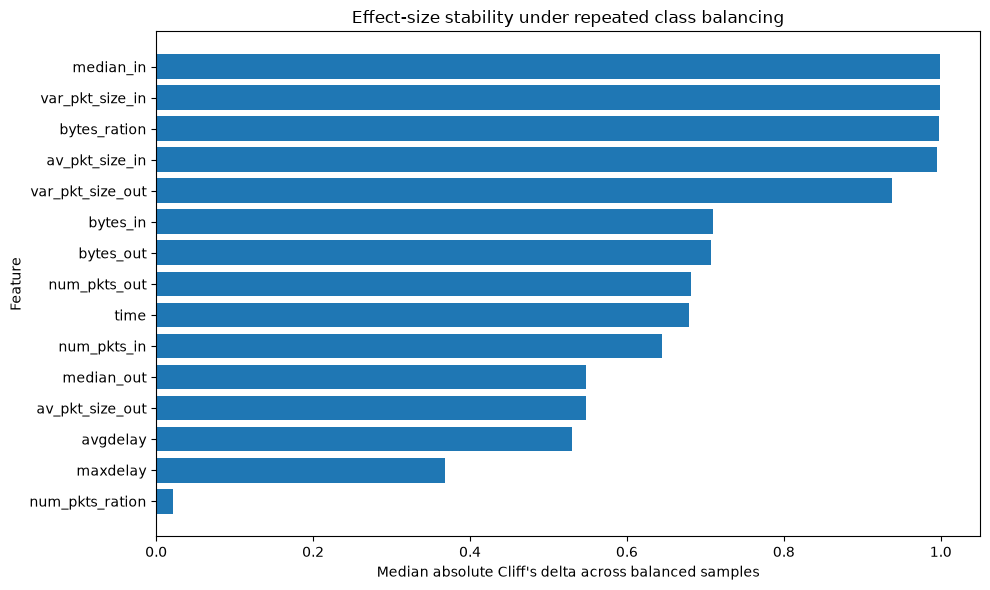

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
ordered = stability.sort_values("median_abs_delta")
ax.barh(ordered.feature, ordered.median_abs_delta)
ax.set(xlabel="Median absolute Cliff's delta across balanced samples",
       ylabel="Feature", title="Effect-size stability under repeated class balancing", xlim=(0, 1.05))
plt.tight_layout()
plt.show()


### Interpretation: Balanced-sampling stability

The original sample contains more malicious than benign flows. Here, all benign flows and an equally sized random subset of malicious flows are compared in each run, using fixed random seeds for reproducibility. Features with consistently high absolute Cliff’s delta and repeated FDR significance are relatively stable to this **specific sampling scheme**. Because the benign subset remains unchanged across runs, the repetitions are not independent replications or confidence intervals. Results may differ under another capture session or traffic source.

## 5. Feature redundancy — Spearman correlation

In [22]:
corr = df[features].corr(method="spearman")
pairs = []
for i, a in enumerate(features):
    for b in features[i + 1:]:
        rho = float(corr.loc[a, b])
        if np.isfinite(rho):
            pairs.append({"feature_a": a, "feature_b": b, "spearman_rho": rho,
                          "abs_rho": abs(rho)})
correlated_pairs = pd.DataFrame(pairs).sort_values("abs_rho", ascending=False)
print("Top 10 absolute Spearman correlations:")
display(correlated_pairs.head(10).round(4))
print("Pairs with |rho| >= 0.95:", int((correlated_pairs.abs_rho >= 0.95).sum()))
if {"av_pkt_size_out", "median_out"}.issubset(df.columns):
    a, b = df["av_pkt_size_out"], df["median_out"]
    print("av_pkt_size_out vs median_out: exact equality:", bool(a.equals(b)))
    print("av_pkt_size_out vs median_out: max absolute difference:", float((a-b).abs().max()))


Top 10 absolute Spearman correlations:


,feature_a,feature_b,spearman_rho,abs_rho
87,av_pkt_size_out,median_out,1.0000,1.0000
80,av_pkt_size_in,median_in,0.9996,0.9996
0,bytes_out,num_pkts_out,0.9954,0.9954
15,num_pkts_out,num_pkts_in,0.9946,0.9946
14,num_pkts_out,bytes_in,0.9922,0.9922
1,bytes_out,bytes_in,0.9902,0.9902
27,bytes_in,num_pkts_in,0.9895,0.9895
2,bytes_out,num_pkts_in,0.9870,0.9870
90,var_pkt_size_in,var_pkt_size_out,0.9142,0.9142
91,var_pkt_size_in,median_in,0.8246,0.8246


Pairs with |rho| >= 0.95: 8
av_pkt_size_out vs median_out: exact equality: False
av_pkt_size_out vs median_out: max absolute difference: 1.021405182655144e-14


### Interpretation: Correlation and redundancy

Large absolute Spearman correlations indicate that two features tend to vary together in this combined sample. They may be redundant for some downstream analyses, but correlation alone does not prove that two columns are identical or interchangeable. The explicit `av_pkt_size_out` versus `median_out` check distinguishes exact equality from nearly identical values. This is a descriptive diagnostic; no features are automatically deleted from the baseline hypothesis tests.

## 6. Save results and summarize limitations

In [23]:
outdir = DATA_DIR / "results"
outdir.mkdir(exist_ok=True)
baseline.to_csv(outdir / "robustness_baseline.csv", index=False)
comparison.to_csv(outdir / "robustness_dedup_comparison.csv", index=False)
stability.to_csv(outdir / "robustness_balanced_sampling.csv", index=False)
correlated_pairs.to_csv(outdir / "robustness_feature_correlations.csv", index=False)
print("Saved four CSV reports to:", outdir.resolve())
print("\nSUMMARY")
print(f"- Full sample: {len(df):,} records; {len(features)} features")
print(f"- Deduplication: {len(df)-len(deduplicated)} rows removed; "
      f"{int(comparison.significance_agrees.sum())}/{len(features)} FDR decisions unchanged")
print(f"- Balanced sampling: {N_REPEATS} repeats, {n_each} observations per class")
print(f"- Features significant in all balanced runs: "
      f"{int((stability.significant_runs == N_REPEATS).sum())}/{len(features)}")


Saved four CSV reports to: /Users/yoelwoldeyes/Downloads/CS746_DoH_Traffic_Analysis/results

SUMMARY
- Full sample: 12,648 records; 15 features
- Deduplication: 57 rows removed; 14/15 FDR decisions unchanged
- Balanced sampling: 20 repeats, 2350 observations per class
- Features significant in all balanced runs: 14/15


### Discussion and Limitations

The robustness analysis evaluated the sensitivity of statistical findings to exact duplicate removal, repeated class-balanced subsampling, and potential feature redundancy using Spearman correlation.

The results indicate that most statistically significant differences between benign Cloudflare and malicious DNSCat2 traffic remained stable under the evaluated conditions. However, the significance decision for `num_pkts_ration` changed after duplicate removal, suggesting that this feature is sensitive to preprocessing decisions.

Repeated balanced subsampling provided additional evidence of stability for the principal findings. Nevertheless, all 2,350 benign observations were reused across sampling iterations, meaning the analysis primarily assessed sensitivity to variation in the malicious sample rather than independent variation in both classes.

Several features exhibited strong correlations, indicating potential redundancy among network-flow measurements.

Important limitations include possible dependence between flows originating from the same host or capture, differences in traffic collection conditions, and uncertainty regarding the original feature scaling. Furthermore, the findings are limited to the selected Cloudflare and DNSCat2 datasets and cannot be generalized to all DNS-over-HTTPS traffic.

No predictive classification model or independent external validation was performed. Therefore, the results demonstrate statistical differences between the selected traffic samples rather than verified malicious-traffic detection performance.

### Conclusion

Overall, the robustness analysis strengthens confidence in the principal statistical findings while identifying sensitivity to duplicate removal and redundancy among selected features. These results support the conclusions of the exploratory and statistical analyses within the evaluated datasets, while emphasizing the need for independent validation before broader generalization.